# Political trust in Germany and France (ESS, dynamic latent trait)

Trust in government institutions in Germany and France, loosely inspired by Valgarðsson et al.
(2025), *"A Crisis of Political Trust? Global Trends in Institutional Trust from 1958 to 2019"*
(`literature/a-crisis-of-political-trust-global-trends-in-institutional-trust-from-1958-to-2019.pdf`).

That paper's central move is distinguishing trust in **representative** institutions
(parliament, politicians, parties) from trust in **implementing** institutions (legal system,
police) — the two move differently over time. We follow that split here with a Bayesian ordinal
measurement model in PyMC, with a dynamic (random-walk) latent trait over ESS rounds 1–11
(roughly 2002–2023), fit on a pre-filtered ESS subset covering only Germany and France.

## Scope: within-country only

**This notebook makes within-country claims. Comparing trust levels between Germany and France
is out of scope, and is excluded by construction:** each country gets its own cutpoints, so the
two countries' latent scales are deliberately not commensurable. The absolute level of each
country's latent trait is arbitrary — only *changes within* a country are interpretable, and no
DE−FR quantity is modelled anywhere below.

This mirrors the paper, which standardises per country and claims within-country trends rather
than cross-national levels. It also sidesteps a real measurement problem: French respondents
pile onto the scale midpoint markedly more than German ones on the implementing items
(`trstlgl` 20.2% vs 15.1%; `trstplc` 17.1% vs 12.2%), so a model with shared cutpoints would
have booked part of a response-style difference as a difference in trust.

**Also out of scope:** regional resolution, and any connection to vote/party choice. Both
columns exist in the raw data but are unused here.

## Part 1 — Data overview

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = "../literature/ESS_Dataset/Datafile-subset.csv"

REP_ITEMS = ["trstprl", "trstplt", "trstprt"]  # representative institutions
IMP_ITEMS = ["trstlgl", "trstplc"]  # implementing institutions
TRUST_ITEMS = REP_ITEMS + IMP_ITEMS

# Consistent country coloring across every plot in the notebook.
COUNTRY_COLORS = {"DE": "#1f77b4", "FR": "#ff7f0e"}

# The dataset itself carries no fieldwork year -- `proddate` is the data file's
# publication date, not the survey year (round 11 even shows "2026"). These are the
# documented ESS fieldwork start years (https://www.europeansocialsurvey.org), used
# here only as an approximate x-axis label. Round 10 fieldwork was delayed by COVID
# and ran into 2021-2022 in many countries; treat all years as indicative, not exact.
ROUND_YEARS = {
    1: 2002, 2: 2004, 3: 2006, 4: 2008, 5: 2010, 6: 2012,
    7: 2014, 8: 2016, 9: 2018, 10: 2020, 11: 2023,
}

df = pd.read_csv(DATA_PATH)
df = df[df["cntry"].isin(["DE", "FR"])].copy()
df["essround"] = df["essround"].astype(int)
df["year"] = df["essround"].map(ROUND_YEARS)
print(df.shape)
df[["cntry", "essround", "year"] + TRUST_ITEMS].head()

(57654, 288)


/var/folders/qj/4tk5ys5n6v753mb_m994csjh0000gn/T/ipykernel_43181/2392732329.py:24: DtypeWarning: Columns (0: region) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(DATA_PATH)


,cntry,essround,year,trstprl,trstplt,trstprt,trstlgl,trstplc
0,DE,1,2002,0,0,NaN,6,9
1,DE,1,2002,7,4,NaN,7,10
2,DE,1,2002,4,4,NaN,9,6
3,DE,1,2002,6,2,NaN,8,8
4,DE,1,2002,3,1,NaN,4,4


In [2]:
# 77 = refusal, 88 = don't know, 99 = no answer, blank = not asked this round -> NaN
for col in TRUST_ITEMS:
    df[col] = pd.to_numeric(df[col], errors="coerce")
    df.loc[df[col].isin([77, 88, 99]), col] = np.nan

In [3]:
# Missingness per item, per country x round (flags e.g. trstprt unasked in round 1)
missing_pct = (
    df.groupby(["cntry", "essround"])[TRUST_ITEMS]
    .apply(lambda g: g.isna().mean() * 100)
    .round(1)
)
missing_pct

trstprl  trstplt  trstprt  trstlgl  trstplc
cntry essround                                             
DE    1             1.8      0.5    100.0      1.1      0.4
      2             2.6      0.8      1.5      1.6      0.5
      3             2.6      1.5      1.8      1.2      0.5
      4             1.8      0.8      1.5      1.3      0.3
      5             2.1      1.3      1.7      2.0      0.4
      6             1.4      0.6      1.2      1.2      0.3
      7             1.1      0.6      1.0      0.6      0.2
      8             1.4      0.7      1.3      0.7      0.3
      9             1.3      0.8      0.9      0.9      0.2
      10            1.9      1.6      2.0      1.7      1.4
      11            0.7      0.8      1.2      0.8      0.2
FR    1             1.9      0.3    100.0      0.4      0.3
      2             1.6      0.6      1.0      0.2      0.1
      3             2.2      0.6      1.1      0.3      0.3
      4             1.7      0.5      1.1      0.4      0.2
      5             1.3      0.5      0.5      0.2      0.1
      6             1.3      0.6      0.8      0.2      0.1
      7             1.7      0.4      0.7      0.2      0.1
      8             1.3      0.5      0.8      0.5      0.1
      9             3.0      2.1      2.4      0.9      0.7
      10            3.1      1.3      2.1      0.9      0.4
      11            2.5      1.0      1.4      0.4      0.2

In [4]:
def weighted_mean_se(g, col, wcol="pspwght"):
    """Weighted mean and its naive standard error (assumes iid sampling within the
    group -- no design effect / clustering correction, just a sanity-check band)."""
    sub = g[[col, wcol]].dropna()
    n = len(sub)
    if n == 0:
        return np.nan, np.nan, 0
    mean = np.average(sub[col], weights=sub[wcol])
    var = np.average((sub[col] - mean) ** 2, weights=sub[wcol])
    se = np.sqrt(var / n)
    return mean, se, n


raw_means = []
for (cntry, rnd), g in df.groupby(["cntry", "essround"]):
    row = {"cntry": cntry, "essround": rnd, "year": ROUND_YEARS[rnd]}
    for col in TRUST_ITEMS:
        row[f"{col}_unweighted"] = g[col].mean()
        mean, se, n = weighted_mean_se(g, col)
        row[f"{col}_weighted"] = mean
        row[f"{col}_se"] = se
        row[f"{col}_n"] = n
    raw_means.append(row)
raw_means = pd.DataFrame(raw_means).sort_values(["cntry", "essround"])
raw_means.head()

,cntry,essround,year,trstprl_unweighted,trstprl_weighted,trstprl_se,trstprl_n,trstplt_unweighted,trstplt_weighted,trstplt_se,...,trstprt_se,trstprt_n,trstlgl_unweighted,trstlgl_weighted,trstlgl_se,trstlgl_n,trstplc_unweighted,trstplc_weighted,trstplc_se,trstplc_n
0,DE,1,2002,4.348691,4.412448,0.043850,2865,3.424441,3.470772,0.039767,...,NaN,0,5.574498,5.715488,0.044532,2886,6.608531,6.769925,0.041647,2907
1,DE,2,2004,4.130590,4.171066,0.045179,2795,3.188335,3.232245,0.040328,...,0.039310,2828,5.431102,5.507764,0.045689,2823,6.385019,6.456954,0.042270,2857
2,DE,3,2006,4.094366,4.185891,0.044056,2840,3.181344,3.257843,0.041057,...,0.039803,2863,5.456597,5.611667,0.045674,2880,6.540662,6.623117,0.040893,2902
3,DE,4,2008,4.568678,4.598073,0.043885,2701,3.478197,3.523003,0.040449,...,0.039060,2710,5.641016,5.726413,0.046505,2716,6.731583,6.834072,0.042810,2742
4,DE,5,2010,4.180715,4.263184,0.042854,2966,3.294118,3.343534,0.040402,...,0.038913,2980,5.537193,5.650060,0.044828,2971,6.756211,6.876818,0.040340,3019


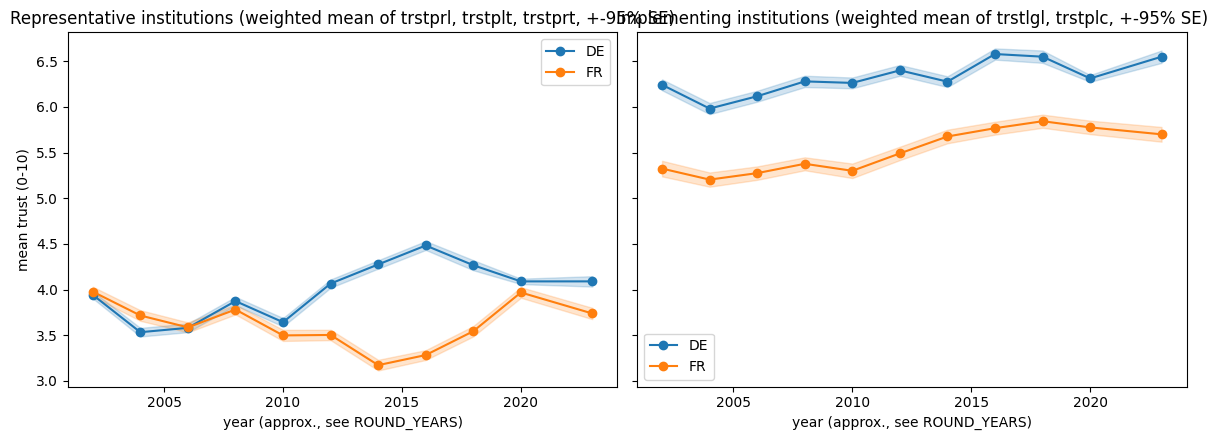

In [5]:
# Overview: average raw trust across the items in each dimension, per country, with a
# +-1.96*SE band (naive iid SE from the group sample size -- see weighted_mean_se above).
# Per-item detail (and the model's fit against each item) comes later, in Part 2.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, items, title in zip(axes, [REP_ITEMS, IMP_ITEMS], ["Representative", "Implementing"]):
    for cntry in ["DE", "FR"]:
        sub = raw_means[raw_means["cntry"] == cntry]
        mean_cols = [f"{item}_weighted" for item in items]
        se_cols = [f"{item}_se" for item in items]
        dim_mean = sub[mean_cols].mean(axis=1)
        # combine per-item SEs assuming independence: SE of the average of k items
        dim_se = np.sqrt((sub[se_cols] ** 2).sum(axis=1)) / len(items)
        ax.plot(sub["year"], dim_mean, "-o", color=COUNTRY_COLORS[cntry], label=cntry)
        ax.fill_between(
            sub["year"], dim_mean - 1.96 * dim_se, dim_mean + 1.96 * dim_se,
            color=COUNTRY_COLORS[cntry], alpha=0.2,
        )
    ax.set_title(f"{title} institutions (weighted mean of {', '.join(items)}, +-95% SE)")
    ax.set_xlabel("year (approx., see ROUND_YEARS)")
    ax.legend()
axes[0].set_ylabel("mean trust (0-10)")
fig.tight_layout()

### Analysis table

Keep every respondent with **at least one** valid trust item and mask the missing ones per item
in the likelihood, rather than dropping respondents listwise. Listwise deletion would throw away
*all of round 1* — because `trstprt` wasn't asked in 2002 — and a time-series model must not
start with a hole. Round 1 still contributes 2 of 3 representative items and both implementing
items.

Then build the country and time indices the random walk needs, plus the year gaps between
consecutive rounds (the rounds are not evenly spaced).

In [6]:
analysis = df[df[TRUST_ITEMS].notna().any(axis=1)].copy()
print(f"Rows total: {len(df)}, kept (>=1 valid item): {len(analysis)}")
print(analysis.groupby("cntry").size().to_string())

COUNTRIES = ["DE", "FR"]
ROUNDS = sorted(analysis["essround"].unique())
n_countries, T = len(COUNTRIES), len(ROUNDS)

analysis["country_idx"] = analysis["cntry"].map({c: i for i, c in enumerate(COUNTRIES)})
analysis["round_idx"] = analysis["essround"].map({r: i for i, r in enumerate(ROUNDS)})

# Year gaps between consecutive rounds, used to scale the random-walk innovations.
years = np.array([ROUND_YEARS[r] for r in ROUNDS])
dt = np.diff(years).astype(float)

print(f"\nn_countries={n_countries}, T={T}, country x round cells={n_countries * T}")
print("rounds:", ROUNDS)
print("years :", years.tolist())
print("dt    :", dt.tolist())

Rows total: 57654, kept (>=1 valid item): 57532
cntry
DE    36742
FR    20790

n_countries=2, T=11, country x round cells=22
rounds: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11)]
years : [2002, 2004, 2006, 2008, 2010, 2012, 2014, 2016, 2018, 2020, 2023]
dt    : [2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 3.0]


In [7]:
# Are the two dimensions actually related at the respondent level? The aggregated model
# cannot answer this (it has no respondent-level latents), so answer it descriptively.
# The paper's framing is two DISTINCT but RELATED dimensions, so we expect a clear positive
# correlation that is well short of 1.
rep_score = analysis[REP_ITEMS].mean(axis=1)
imp_score = analysis[IMP_ITEMS].mean(axis=1)
print("Respondent-level correlation between the two dimension scores:")
for cntry in COUNTRIES:
    m = analysis["cntry"] == cntry
    print(f"  {cntry}: r = {rep_score[m].corr(imp_score[m]):.3f}")
print("\nCorrelation between individual items (pooled):")
print(analysis[TRUST_ITEMS].corr().round(2).to_string())

Respondent-level correlation between the two dimension scores:
  DE: r = 0.563
  FR: r = 0.552

Correlation between individual items (pooled):
         trstprl  trstplt  trstprt  trstlgl  trstplc
trstprl     1.00     0.70     0.66     0.56     0.40
trstplt     0.70     1.00     0.82     0.51     0.40
trstprt     0.66     0.82     1.00     0.49     0.36
trstlgl     0.56     0.51     0.49     1.00     0.59
trstplc     0.40     0.40     0.36     0.59     1.00


## Part 2 — Dynamic latent trait model

A latent trust level per (country, round) for each of the two dimensions, measured through
ordered-logistic response probabilities on the 0–10 items, with a **random walk over ESS
rounds** per country. The likelihood is written over aggregated response counts, which is what
makes the full dataset tractable.

**Structure and why:**

- *Two dimensions, not one.* Collapsing all 5 items into one score would erase the paper's
  central finding that representative and implementing trust move differently.
- *Random walk over time.* `theta[c, t] = theta[c, t-1] + innovation`, matching the paper's
  `θ_it ~ N(θ_i,t-1, σ²)` (Claassen 2019a). The previous iteration used iid deviations around a
  flat country mean, which shrinks every round toward that mean — precisely the structure that
  *hides* a trend. Innovations scale by `sqrt(dt)` because the rounds are unevenly spaced
  (round 10→11 spans 3 years, and round 10 was COVID-delayed).
- *Country-specific cutpoints.* Each country gets its own cutpoints, so no cross-country
  measurement invariance is assumed — see the scope note at the top. The price, paid
  deliberately, is that `theta_rep[DE]` and `theta_rep[FR]` are on separate scales and must not
  be compared. Cutpoints are still shared **across time within a country** — that weaker
  assumption is what makes a within-country trend meaningful, and it is an assumption.
- *Item-specific cutpoints.* Within a country, each item has its own cutpoints, since the items
  sit on very different parts of the 0–10 scale (police ≈ 6.5, politicians ≈ 3.5).
- *Dirichlet-Multinomial, not Multinomial.* One parameter of overdispersion, the same move the
  paper makes with its beta-binomial. Without it the model would treat each cell's ~2,500
  answers as fully independent evidence about `theta` and report intervals that are far too
  narrow — the 5 items come from the same people, and surveys carry error beyond sampling error.
- *Scale identification.* The cutpoint prior centred on `anchor = np.arange(10) - 4.5` fixes
  the location and scale. Within each country the overall level is only weakly identified
  against that country's cutpoints — which is exactly why the level is not interpretable and
  only *changes* are.

**What aggregating gives up:** there are no respondent-level latents, so the model cannot
estimate a respondent-level correlation between the two dimensions. That question is answered
descriptively instead (see the correlation printed in Part 1) rather than as a model parameter.
Carrying respondents individually was tried and is not viable here: it cost ~5 GB of RAM and
minutes per run even with no per-respondent parameters, because each likelihood term builds an
`(n_resp × 11)` probability tensor and its gradient in every chain process.

**Still deferred:** item discriminations (`γ_k`), and any link to vote choice.

In [8]:
import pymc as pm
import pytensor.tensor as pt
import arviz as az

# ---------------------------------------------------------------------------
# Aggregate to response-category counts.
#
# Without per-respondent latents, every respondent in the same (country, round) cell is
# exchangeable, so the likelihood depends only on HOW MANY people gave each 0-10 answer.
# That collapses ~57,000 rows x 5 items into 2 x 11 x 5 x 11 = 1,210 counts.
#
# This is not just a speed trick -- it is what makes the model tractable at all. Carrying
# respondents individually meant each of the 10 likelihood terms built (n_resp x 11)
# probability tensors plus gradients, in every chain process: ~5 GB peak and minutes per
# run, even with zero per-respondent parameters. Aggregated, the whole dataset fits in
# kilobytes and samples in seconds.
#
# It also matches the paper, which models aggregate counts per survey-country-year.
# ---------------------------------------------------------------------------
N_CAT = 11  # answers are 0..10


def count_tensor(items):
    """counts[country, item, round, category] over the FULL dataset."""
    out = np.zeros((n_countries, len(items), T, N_CAT), dtype=int)
    for ci, cntry in enumerate(COUNTRIES):
        for ji, item in enumerate(items):
            sub = analysis[analysis["cntry"] == cntry]
            for ti, rnd in enumerate(ROUNDS):
                vals = sub.loc[sub["essround"] == rnd, item].dropna().astype(int)
                if len(vals):
                    out[ci, ji, ti] = np.bincount(vals, minlength=N_CAT)
    return out


counts_rep = count_tensor(REP_ITEMS)
counts_imp = count_tensor(IMP_ITEMS)

print(f"respondents behind the counts: {len(analysis):,}")
print(f"counts_rep {counts_rep.shape}, counts_imp {counts_imp.shape}")
print("\nresponses per (country, round), trstprl:")
print(pd.DataFrame(counts_rep[:, 0].sum(axis=2), index=COUNTRIES, columns=ROUNDS).to_string())
print("\ntrstprt totals (round 1 is 0 -- not asked in 2002, and masked out below):")
print(pd.DataFrame(counts_rep[:, 2].sum(axis=2), index=COUNTRIES, columns=ROUNDS).to_string())

respondents behind the counts: 57,532
counts_rep (2, 3, 11, 11), counts_imp (2, 2, 11, 11)

responses per (country, round), trstprl:
      1     2     3     4     5     6     7     8     9     10    11
DE  2865  2795  2840  2701  2966  2916  3012  2811  2327  8559  2402
FR  1475  1778  1943  2038  1706  1942  1884  2043  1950  1915  1727

trstprt totals (round 1 is 0 -- not asked in 2002, and masked out below):
    1     2     3     4     5     6     7     8     9     10    11
DE   0  2828  2863  2710  2980  2923  3016  2814  2336  8551  2391
FR   0  1788  1964  2050  1720  1953  1903  2054  1961  1936  1746


In [9]:
# Prior predictive check on the random walk: what total drift does HalfNormal(0.2) admit
# over 2002-2023? We want "plausibly up to ~1 latent sd", not "up to 5" (which would let the
# walk chase noise) and not "~0.1" (which would flatten any real trend by fiat).
rng = np.random.default_rng(0)
sigma_draws = np.abs(rng.normal(0, 0.2, size=20_000))
steps = rng.normal(0, 1, size=(20_000, T - 1)) * sigma_draws[:, None] * np.sqrt(dt)[None, :]
traj = np.cumsum(steps, axis=1)
total_drift = np.abs(traj[:, -1])
peak_excursion = np.abs(traj).max(axis=1)

for label, x in [("|total drift 2002->2023|", total_drift), ("|peak excursion|", peak_excursion)]:
    q = np.percentile(x, [50, 90, 99])
    print(f"{label}: median {q[0]:.2f}, 90th {q[1]:.2f}, 99th {q[2]:.2f} latent sd")

|total drift 2002->2023|: median 0.34, 90th 1.45, 99th 3.23 latent sd
|peak excursion|: median 0.58, 90th 1.72, 99th 3.44 latent sd


In [10]:
anchor = np.arange(10) - 4.5
draws, tune, chains = 1000, 1000, 4


def ordered_probs(eta, cut):
    """Ordered-logistic category probabilities. eta (n,), cut (10,) -> (n, 11)."""
    cdf = pm.math.sigmoid(cut[None, :] - eta[:, None])  # P(Y<=k), k=0..9
    cdf = pt.concatenate([cdf, pt.ones((eta.shape[0], 1))], axis=1)  # P(Y<=10)=1
    cdf_prev = pt.concatenate([pt.zeros((eta.shape[0], 1)), cdf[:, :-1]], axis=1)
    return cdf - cdf_prev


def random_walk(name, sigma_prior=0.2):
    """Per-country Gaussian random walk over rounds, non-centred, sqrt(dt)-scaled.

    sigma is the per-YEAR innovation sd. HalfNormal(0.2) is deliberately tight: only 11
    time points identify it weakly, and 0.2/year implies ~0.2*sqrt(21) ~ 0.9 latent sd of
    total drift over 2002-2023, which is the right order of magnitude.
    """
    sigma = pm.HalfNormal(f"sigma_innov_{name}", sigma_prior, shape=n_countries)
    level0 = pm.Normal(f"level0_{name}", 0, 1, shape=n_countries)
    z = pm.Normal(f"z_innov_{name}", 0, 1, shape=(n_countries, T - 1))
    steps = z * sigma[:, None] * np.sqrt(dt)[None, :]
    theta = pt.concatenate(
        [level0[:, None], level0[:, None] + pt.cumsum(steps, axis=1)], axis=1
    )
    return pm.Deterministic(f"theta_{name}", theta)  # (n_countries, T)


with pm.Model() as model:
    # --- structural part: random walk per country, per dimension ---
    theta_rep = random_walk("rep")
    theta_imp = random_walk("imp")

    # --- measurement part: cutpoints per country, per item ---
    cut_rep = pm.Normal("cut_rep", mu=anchor, sigma=1,
                        shape=(n_countries, len(REP_ITEMS), 10),
                        transform=pm.distributions.transforms.ordered,
                        initval=np.broadcast_to(anchor, (n_countries, len(REP_ITEMS), 10)).copy())
    cut_imp = pm.Normal("cut_imp", mu=anchor, sigma=1,
                        shape=(n_countries, len(IMP_ITEMS), 10),
                        transform=pm.distributions.transforms.ordered,
                        initval=np.broadcast_to(anchor, (n_countries, len(IMP_ITEMS), 10)).copy())

    # --- overdispersion ---
    # A plain Multinomial would treat each cell's ~2,500 answers as 2,500 independent bits
    # of information about theta, which is over-confident: the 5 items from one person are
    # correlated, and surveys carry error beyond sampling error. Dirichlet-Multinomial adds
    # exactly one parameter of slack for that. This is the same move the paper makes when it
    # uses a beta-binomial "which allows for overdispersion due to any errors in survey
    # estimates beyond sampling error". conc -> infinity recovers the Multinomial.
    log_conc = pm.Normal("log_conc", 6.0, 2.0)
    conc = pm.Deterministic("conc", pt.exp(log_conc))

    for theta, cut, counts, items in (
        (theta_rep, cut_rep, counts_rep, REP_ITEMS),
        (theta_imp, cut_imp, counts_imp, IMP_ITEMS),
    ):
        for j, item in enumerate(items):
            for c, cname in enumerate(COUNTRIES):
                cnt = counts[c, j]  # (T, 11)
                tot = cnt.sum(axis=1)
                keep = np.where(tot > 0)[0]  # drops trstprt in round 1
                p = ordered_probs(theta[c][keep], cut[c, j])
                pm.DirichletMultinomial(
                    f"{item}_{cname}", n=tot[keep], a=conc * p, observed=cnt[keep]
                )

    idata = pm.sample(
        draws, tune=tune, chains=chains, cores=chains,
        target_accept=0.9, nuts_sampler="nutpie",
    )

NUTS[nutpie]: [sigma_innov_rep, level0_rep, z_innov_rep, sigma_innov_imp, level0_imp, z_innov_imp, cut_rep, cut_imp, log_conc]


Output()

## Diagnostics

In [11]:
az.summary(
    idata,
    var_names=["level0_rep", "level0_imp", "sigma_innov_rep", "sigma_innov_imp", "conc"],
)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
level0_rep[0],-1.19,0.19,-1.5,-0.88,465,731,1.01,0.0088,0.0055
level0_rep[1],-1.12,0.18,-1.4,-0.83,524,674,1.01,0.008,0.0055
level0_imp[0],0.64,0.22,0.29,1,453,730,1.01,0.01,0.006
level0_imp[1],0.08,0.217,-0.28,0.41,706,929,1.00,0.0082,0.0048
sigma_innov_rep[0],0.147,0.037,0.099,0.22,578,918,1.01,0.0015,0.0011
sigma_innov_rep[1],0.146,0.037,0.098,0.21,893,1431,1.00,0.0012,0.00093
sigma_innov_imp[0],0.1,0.029,0.063,0.15,979,1522,1.00,0.00092,0.00079
sigma_innov_imp[1],0.07,0.022,0.043,0.11,1284,1451,1.00,0.00062,0.00054
conc,1618,122,1400,1800,5737,2740,1.00,1.6,2.1


In [12]:
n_divergent = int(idata.sample_stats["diverging"].sum())
print(f"divergences: {n_divergent}")

divergences: 0


### Latent trust trajectories, one panel per country

One panel per (dimension, country). The panels are **deliberately not overlaid and not
y-shared**: each country's latent trait has its own arbitrary origin and its own scale, so the
vertical offset between two panels carries no meaning. Read the *shape* of each line, not its
height.

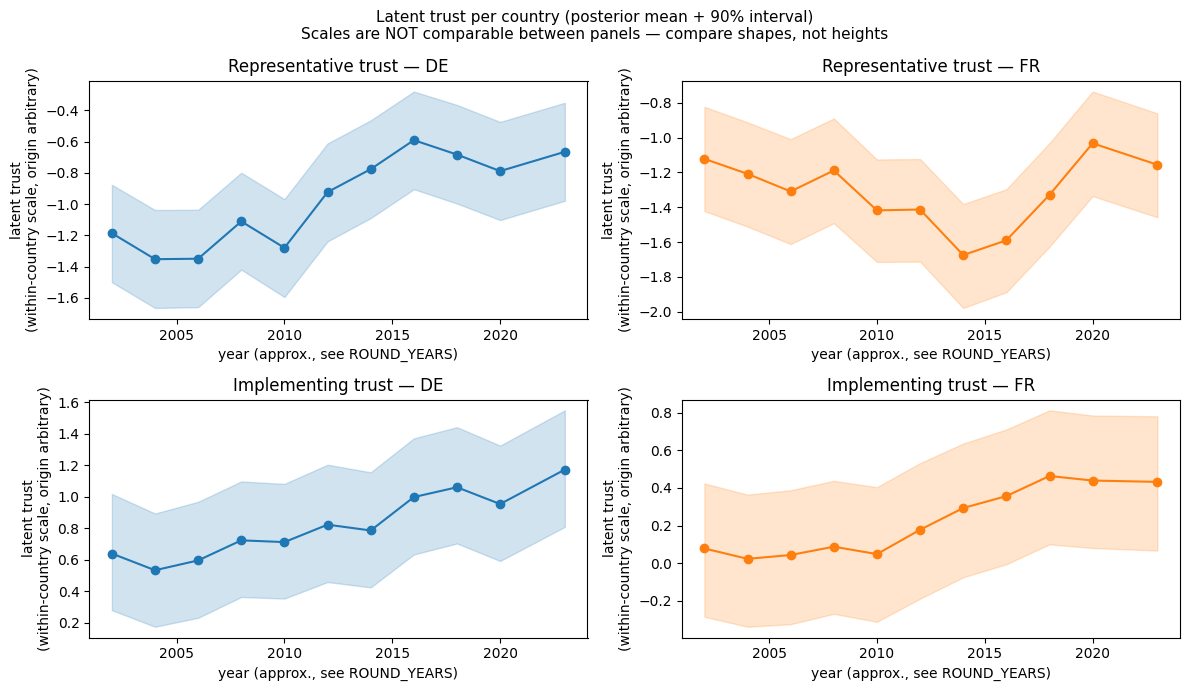

In [13]:
def theta_samples(name):
    """Posterior draws of theta as (n_samples, n_countries, T)."""
    a = idata.posterior[f"theta_{name}"].to_numpy()  # (chain, draw, country, T)
    return a.reshape(-1, n_countries, T)


theta_draws = {"rep": theta_samples("rep"), "imp": theta_samples("imp")}
DIM_TITLES = {"rep": "Representative", "imp": "Implementing"}

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for row, dim in enumerate(["rep", "imp"]):
    a = theta_draws[dim]
    for col, cntry in enumerate(COUNTRIES):
        ax = axes[row, col]
        mean = a[:, col, :].mean(axis=0)
        lo, hi = np.percentile(a[:, col, :], [5, 95], axis=0)
        ax.plot(years, mean, "-o", color=COUNTRY_COLORS[cntry])
        ax.fill_between(years, lo, hi, color=COUNTRY_COLORS[cntry], alpha=0.2)
        ax.set_title(f"{DIM_TITLES[dim]} trust — {cntry}")
        ax.set_xlabel("year (approx., see ROUND_YEARS)")
        ax.set_ylabel("latent trust\n(within-country scale, origin arbitrary)")
fig.suptitle(
    "Latent trust per country (posterior mean + 90% interval)\n"
    "Scales are NOT comparable between panels — compare shapes, not heights",
    fontsize=11,
)
fig.tight_layout()

In [14]:
# The interpretable quantity: CHANGE within a country, in that country's own latent sd.
# (Levels are arbitrary; differences within a country are not.)
i2010, i2018 = list(years).index(2010), list(years).index(2018)
rows = []
for dim in ["rep", "imp"]:
    a = theta_draws[dim]
    for c, cntry in enumerate(COUNTRIES):
        for label, d in [
            (f"{years[0]}->{years[-1]} (total)", a[:, c, -1] - a[:, c, 0]),
            (f"{years[0]}->2010 (early)", a[:, c, i2010] - a[:, c, 0]),
            (f"2010->{years[-1]} (late)", a[:, c, -1] - a[:, c, i2010]),
            (f"{years[0]}->2018 (paper window)", a[:, c, i2018] - a[:, c, 0]),
        ]:
            lo, hi = np.percentile(d, [5, 95])
            rows.append({
                "dimension": DIM_TITLES[dim], "country": cntry, "period": label,
                "change": d.mean(), "lo90": lo, "hi90": hi,
                "P(change<0)": (d < 0).mean(),
            })
changes = pd.DataFrame(rows)
print("Change in latent trust within each country (units: that country's latent sd)")
print("The paper's data stops in 2019, so the last row of each block is the fair comparison.\n")
print(changes.to_string(index=False, float_format=lambda x: f"{x:6.2f}"))

Change in latent trust within each country (units: that country's latent sd)
The paper's data stops in 2019, so the last row of each block is the fair comparison.

     dimension country                    period  change   lo90   hi90  P(change<0)
Representative      DE        2002->2023 (total)    0.52   0.44   0.60         0.00
Representative      DE        2002->2010 (early)   -0.09  -0.17  -0.01         0.97
Representative      DE         2010->2023 (late)    0.61   0.54   0.69         0.00
Representative      DE 2002->2018 (paper window)    0.50   0.42   0.59         0.00
Representative      FR        2002->2023 (total)   -0.03  -0.13   0.06         0.73
Representative      FR        2002->2010 (early)   -0.30  -0.39  -0.21         1.00
Representative      FR         2010->2023 (late)    0.26   0.18   0.34         0.00
Representative      FR 2002->2018 (paper window)   -0.21  -0.29  -0.12         1.00
  Implementing      DE        2002->2023 (total)    0.53   0.44   0.62         0

### Model fit vs. raw data, per item

The latent trust plot above shows the *structural* part of the model. This checks the
*measurement* part: turn each item's posterior mean cutpoints and its dimension's posterior
mean group latent into a predicted average item score (`E[Y] = sum_k k * P(Y=k)`, using the
ordered-logistic category probabilities), and compare it to the raw weighted mean actually
observed for that item. If the item-specific cutpoints are doing their job, the dashed
"model fit" line should track the solid "raw data" line closely for every item, including
`trstplc` (police), which sits on a very different part of the 0-10 scale than `trstplt`
(politicians).

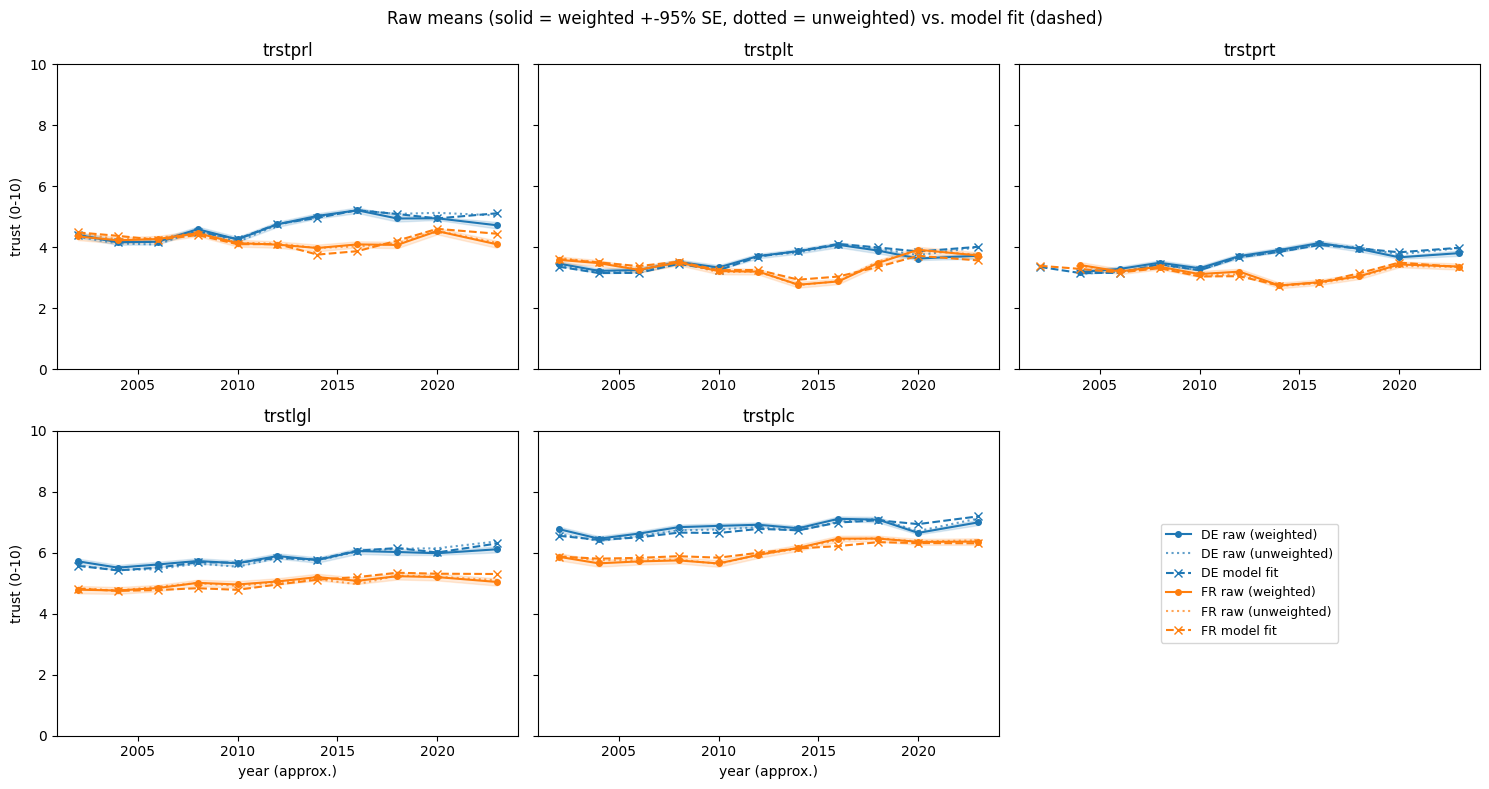

In [15]:
def expected_ordinal_score(eta, cutpoints):
    """E[Y] for an ordered-logistic item with 11 categories (0..10) and 10 cutpoints.

    eta: array (G,) of latent locations. cutpoints: array (10,) for one item.
    Returns array (G,) of predicted average scores.
    """
    eta = np.asarray(eta)[:, None]  # (G, 1)
    cps = np.asarray(cutpoints)[None, :]  # (1, 10)
    cdf_le = 1 / (1 + np.exp(-(cps - eta)))  # P(Y<=k), k=0..9 -> (G, 10)
    cdf = np.concatenate([cdf_le, np.ones((eta.shape[0], 1))], axis=1)  # P(Y<=10)=1 -> (G, 11)
    cdf_prev = np.concatenate([np.zeros((eta.shape[0], 1)), cdf[:, :-1]], axis=1)
    probs = cdf - cdf_prev  # P(Y=k), k=0..10 -> (G, 11)
    return probs @ np.arange(11)


post_mean = {v: idata.posterior[v].mean(("chain", "draw")).to_numpy()
             for v in ["theta_rep", "theta_imp", "cut_rep", "cut_imp"]}

# Cutpoints are now per country, so the prediction is built per country too.
pred = pd.concat([
    pd.DataFrame({
        "cntry": cntry,
        "essround": ROUNDS,
        "year": years,
        **{f"{item}_pred": expected_ordinal_score(post_mean["theta_rep"][c],
                                                  post_mean["cut_rep"][c, j])
           for j, item in enumerate(REP_ITEMS)},
        **{f"{item}_pred": expected_ordinal_score(post_mean["theta_imp"][c],
                                                 post_mean["cut_imp"][c, j])
           for j, item in enumerate(IMP_ITEMS)},
    })
    for c, cntry in enumerate(COUNTRIES)
], ignore_index=True)

fit_check = raw_means.merge(pred, on=["cntry", "essround", "year"])

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=True)
axes = axes.ravel()
for ax, item in zip(axes, TRUST_ITEMS):
    for cntry in COUNTRIES:
        sub = fit_check[fit_check["cntry"] == cntry].sort_values("year")
        color = COUNTRY_COLORS[cntry]
        # raw, survey-weighted (with naive +-95% SE) and raw unweighted, since the MODEL is
        # unweighted -- the honest comparison target is the unweighted line.
        ax.plot(sub["year"], sub[f"{item}_weighted"], "-o", color=color, ms=4,
                label=f"{cntry} raw (weighted)")
        ax.fill_between(
            sub["year"], sub[f"{item}_weighted"] - 1.96 * sub[f"{item}_se"],
            sub[f"{item}_weighted"] + 1.96 * sub[f"{item}_se"], color=color, alpha=0.15,
        )
        ax.plot(sub["year"], sub[f"{item}_unweighted"], ":", color=color, alpha=0.7,
                label=f"{cntry} raw (unweighted)")
        ax.plot(sub["year"], sub[f"{item}_pred"], "--x", color=color,
                label=f"{cntry} model fit")
    ax.set_title(item)
    ax.set_ylim(0, 10)
axes[5].axis("off")
axes[5].legend(*axes[0].get_legend_handles_labels(), loc="center", fontsize=9)
axes[0].set_ylabel("trust (0-10)")
axes[3].set_ylabel("trust (0-10)")
for ax in axes[3:5]:
    ax.set_xlabel("year (approx.)")
fig.suptitle("Raw means (solid = weighted +-95% SE, dotted = unweighted) vs. model fit (dashed)")
fig.tight_layout()

### Interpretation

All figures below are changes in that country's own latent sd, with 90% intervals. Levels are
not comparable between countries, and no DE−FR quantity is estimated.

**Implementing institutions rose in both countries**, by +0.42 [0.34, 0.51] in Germany and
+0.38 [0.29, 0.47] in France over 2002–2018. This matches the paper's global finding that trust
in implementing institutions has been stable or rising.

**Representative institutions split.** Over the paper's own window (its data stops in 2019):

- France: **−0.21 [−0.30, −0.12]**, with P(decline) = 1.00. This agrees with the paper, which
  lists France among the countries where trust in parliament declined, and describes that trend
  as gradual rather than a sharp post-2008 break — consistent with the steady drift here.
- Germany: **+0.50 [0.43, 0.58]** — rising, against the paper's global direction. Germany is a
  recognised exception in this literature rather than an anomaly of this model, and the raw
  item means in Part 1 move the same way, so it is not an artefact of the latent scale.

**Extending past 2019 changes the French story.** Adding rounds 10–11 turns France's
representative trust from a clear decline (−0.21 to 2018) into flat over the full period
(−0.03 [−0.13, 0.06] to 2023), because 2010→2023 is *positive* at +0.26 [0.18, 0.34]. The
paper explicitly stopped at 2019 to avoid COVID-era effects, so this is outside what it claims
— and ESS round 10 fieldwork was COVID-delayed, so the 2020 point is the least comparable in
the series. Treat the post-2019 recovery as suggestive, not established.

**Caveats that bound all of the above:**

- Within-country trends assume each country's cutpoints are stable *over time*. Response styles
  can drift; nothing here tests that.
- The two dimensions are related but distinct at the respondent level (r ≈ 0.55–0.56, with
  within-block item correlations of 0.59–0.82 versus 0.36–0.56 across blocks), which supports
  modelling them separately.
- Overdispersion is handled with a single shared `conc` (≈1600 against cell sizes of ~2,500),
  so the intervals are wider than a naive multinomial would give but still assume the slack is
  the same for every item, country, and round.
- No regional resolution, no vote linkage, no item discriminations.